# L6 — How far can a scan's VARI be trusted? A weather confidence for each flight

*Krops weather notebooks · 4 of 4 · [1 — L5 water stress](01_L5_water_stress.ipynb) · [2 — L8 spreading window](02_L8_spreading_window.ipynb) · [3 — L5 water balance](03_L5_water_balance.ipynb) · process: [VARI_CONFIDENCE.md](VARI_CONFIDENCE.md)*

**Status: prototype.** The rule lives in `l6_vari_confidence.py` and runs on the backend after a phone syncs a scan. Every factor below is a guess until L9 calibrates it; the L5 rule (P30, WeatherKit first, checked NASA POWER as the fallback) and the 25 mm heavy-rain line are the decided ones, reused unchanged.

## Problem statement

Krops reads palm crowns from drone photos and turns their colour into an index. VARI = (G − R) / (G + R − B) needs only an RGB camera, but it also moves for reasons that have nothing to do with nutrients:

- **The flight.** A low sun casts long shadows into the crowns. Broken cloud changes the light from one photo to the next. Leaves still wet from rain look darker.
- **The water.** A palm short of water can pale like a palm short of nutrients. L5 flags this as `water_stress` when the last 30 days brought under 60 mm.

**The question:** for each scan, how far can its VARI be trusted as a sign of nutrient status? The answer is a confidence between 0 and 1, a label (*tinggi*, *sedang*, *rendah*) and the reasons.

## Thinking flow

1. VARI per crown on the sample photo
2. The factors
3. Two flights at the trial plot
4. When to fly: the sun by hour and month
5. Backcast: a 10:00 flight every day, 2022–2025
6. Where this leaves us

In [1]:
import re
from datetime import date, datetime, time, timedelta, timezone
from pathlib import Path

import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Picture, display
from PIL import Image

import krops_rules as rules
import krops_weather as kw
import l6_vari_confidence as conf
import nasa_power_job as job
from krops_weather import LAT, LON, SITE_NAME, TZ

kw.use_chart_style()
PHOTO = Path("..") / "segmentation" / "DJI_15-copy_jpg.rf.947a177207587775a6d0377b1173ca20.jpg"
PLOT = {"plot_id": "trial", "lat": LAT, "lon": LON}  # the trial plot; coordinates come from .env and aren't printed
print(f"{SITE_NAME} · labels: {dict((n, f'≥ {f}') for f, n in conf.LABELS)} · otherwise rendah")

Tanjung Pinang · labels: {'tinggi': '≥ 0.8', 'sedang': '≥ 0.5'} · otherwise rendah


### 1. VARI per crown on the sample photo

**Why we ask.** The confidence is about VARI, so first a look at what VARI is per crown. The segmentation notebooks find palms with the Core ML detector and cut each crown out with SAM; the SAM weights aren't in the repo, so this demo uses the photo's Roboflow boxes as crowns and keeps only leaf pixels inside them.

**Demo rules, not production:** a leaf pixel is greener than it is red and blue; a pixel darker than 40 (of 255) is shadow; a pixel where G + R − B is near 0 is dropped, because VARI blows up there. The photo has no capture time or place (Roboflow strips EXIF), so it can't be paired with real weather. Sections 3 and 5 use made-up flight times at the trial plot, with the real weather of those mornings.

12 crowns · VARI median across crowns 0.164


,leaf share,VARI median,VARI IQR
crown,,,
0,0.717,0.193,0.104
1,0.793,0.147,0.076
2,0.856,0.189,0.120
3,0.773,0.162,0.088
4,0.760,0.195,0.124
5,0.865,0.168,0.095
6,0.861,0.167,0.095
7,0.756,0.148,0.108
8,0.684,0.158,0.114


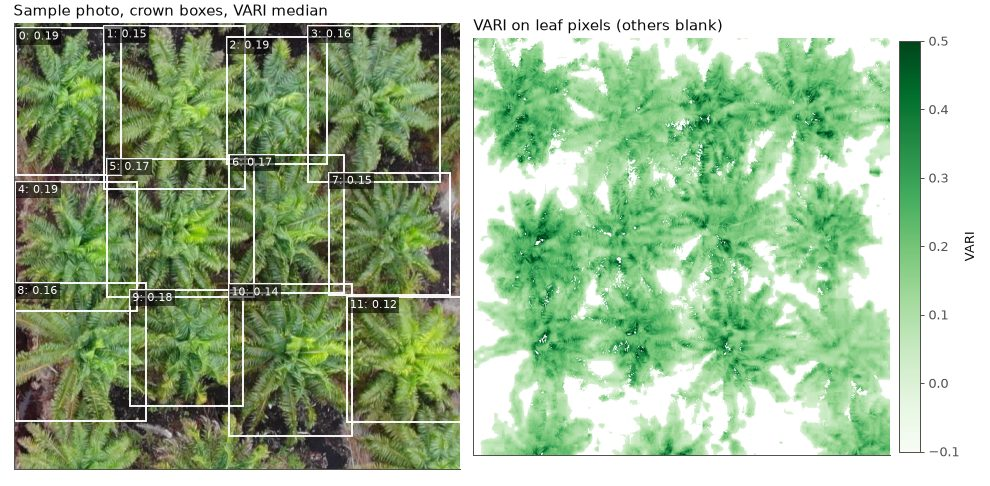

In [2]:
DARK_MAX = 40          # demo only: mean RGB under this is shadow
DENOMINATOR_MIN = 10   # demo only: |G + R − B| under this makes VARI unstable

rgb = np.asarray(Image.open(PHOTO).convert("RGB"), dtype=float)
R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
den = G + R - B
with np.errstate(divide="ignore", invalid="ignore"):
    vari = np.where(np.abs(den) >= DENOMINATOR_MIN, (G - R) / den, np.nan)
leaf = (G > R) & (G > B) & (rgb.mean(axis=2) > DARK_MAX) & np.isfinite(vari)

xml = PHOTO.with_suffix(".xml").read_text()
boxes = [tuple(int(re.search(f"<{k}>(\\d+)</{k}>", obj).group(1)) for k in ("xmin", "ymin", "xmax", "ymax"))
         for obj in re.findall(r"<object>(.*?)</object>", xml, re.S)]
rows = []
for i, (x1, y1, x2, y2) in enumerate(boxes):
    values = vari[y1:y2, x1:x2][leaf[y1:y2, x1:x2]]
    q1, med, q3 = np.percentile(values, [25, 50, 75]) if values.size else (np.nan,) * 3
    rows.append({"crown": i, "leaf share": values.size / ((x2 - x1) * (y2 - y1)), "VARI median": med, "VARI IQR": q3 - q1})
crowns = pd.DataFrame(rows).set_index("crown")
print(f"{len(boxes)} crowns · VARI median across crowns {crowns['VARI median'].median():.3f}")
display(crowns.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
axes[0].imshow(rgb.astype(np.uint8))
for i, (x1, y1, x2, y2) in enumerate(boxes):
    axes[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="white", linewidth=1.5))
    axes[0].text(x1 + 4, y1 + 16, f"{i}: {crowns.loc[i, 'VARI median']:.2f}", color="white", fontsize=9,
                 bbox={"facecolor": "black", "alpha": 0.55, "pad": 2, "linewidth": 0})
axes[0].set_title("Sample photo, crown boxes, VARI median", loc="left")
shown = np.where(leaf, np.clip(vari, -0.1, 0.5), np.nan)
image = axes[1].imshow(shown, cmap="Greens", vmin=-0.1, vmax=0.5)
axes[1].set_title("VARI on leaf pixels (others blank)", loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.02, label="VARI")
fig.tight_layout()
buffer = io.BytesIO()
fig.savefig(buffer, format="jpeg", dpi=90, pil_kwargs={"quality": 82})  # a photo: JPEG keeps the notebook small
plt.close(fig)
display(Picture(buffer.getvalue()))

**What we found** *(run on 14 Oct 2026)*

- 12 crowns. Leaf pixels make up 68–87% of each box; crown medians run from **0.12 to 0.19** (median 0.16).
- Inside a crown, VARI spreads by 0.06–0.12 between its quartiles: as much as the difference between crowns. Shadowed and sunlit fronds of one palm already read differently, which is why the light at the moment of the flight matters.
- A demo: boxes, not SAM masks, and a rough leaf rule. Production VARI comes from the L1 step on the phone.

### 2. The factors

Each input becomes a factor between 0 and 1, read straight from `l6_vari_confidence.py` below so the notebook can't drift from the code. The confidence is the product: *pengukuran* (sun × cloud × wet leaves) × *air* (water).

| Input | Source, in order |
| --- | --- |
| Lowest sun elevation during the flight | `solar.py`, from the flight's start, middle and end |
| Cloud over the flight hours | WeatherKit hourly → WeatherKit daytime (07:00–19:00) → NASA POWER clearness for the day |
| Rain in the 6 and 24 hours before take-off | WeatherKit hourly → WeatherKit day parts (24 h only) |
| P30 on the scan day | The decided L5 rule: WeatherKit first, checked NASA POWER as the fallback |

An input nobody knows never scores 1, and the result is marked `final: false` until it is known.

In [3]:
factors = pd.DataFrame(
    [("sun", f"lowest elevation ≥ {floor:g}°", value) for floor, value, _ in conf.SUN_BANDS]
    + [("sun", f"under {conf.SUN_BANDS[-1][0]:g}°", conf.SUN_VERY_LOW), ("sun", "unknown", conf.SUN_UNKNOWN)]
    + [("cloud", f"{name} (clear ≤ {conf.CLOUD_CLEAR_MAX:g}, overcast ≥ {conf.CLOUD_OVERCAST_MIN:g})", value)
       for name, value in conf.CLOUD_FACTOR.items()]
    + [("wet leaves", {"dry": "dry", "rain_before": f"≥ {conf.WET_RAIN_MM:g} mm in {conf.WET_HOURS} h before",
                       "heavy_day_before": f"> {rules.HEAVY_RAIN_MM:g} mm in 24 h before (decided line)",
                       "unknown": "unknown"}[name], value) for name, value in conf.WET_FACTOR.items()]
    + [("water (L5)", {"ok": "not stressed, WeatherKit", "fallback": "not stressed, NASA POWER fallback",
                       "water_stress": f"P30 under {rules.P30_THRESHOLD_MM:g} mm", "unknown": "unknown"}[name], value)
       for name, value in conf.WATER_FACTOR.items()],
    columns=["input", "when", "factor"]).set_index(["input", "when"])
display(factors)

factor
input      when                                          
sun        lowest elevation ≥ 45°                    1.00
           lowest elevation ≥ 30°                    0.85
           lowest elevation ≥ 15°                    0.60
           under 15°                                 0.30
           unknown                                   0.60
cloud      clear (clear ≤ 0.2, overcast ≥ 0.8)       1.00
           broken (clear ≤ 0.2, overcast ≥ 0.8)      0.70
           overcast (clear ≤ 0.2, overcast ≥ 0.8)    0.85
           unknown (clear ≤ 0.2, overcast ≥ 0.8)     0.80
wet leaves dry                                       1.00
           ≥ 0.5 mm in 6 h before                    0.70
           > 25 mm in 24 h before (decided line)     0.85
           unknown                                   0.85
water (L5) not stressed, WeatherKit                  1.00
           not stressed, NASA POWER fallback         0.90
           P30 under 60 mm                           0.60
           unknown                                   0.75

### 3. Two flights at the trial plot

**Why we ask.** To see the rule work on real weather. Both flights are made up, at the same time of day, 09:40–10:05 WIB, at the trial plot: one on an ordinary day, **15 Sep 2026**, and one on the wet morning of **1 Jun 2023** (the day WeatherKit dropped from one request and the retry recovered). The weather is real: WeatherKit hourly and daily history for the site, and NASA POWER, all from the saved responses in `data/raw/`.

In [4]:
WK_DAILY = kw.fetch_weatherkit_history(date(2021, 8, 1), date(2026, 10, 8), forever=True)["rain_mm"].dropna().to_dict()
nasa_hist, _, _ = kw.fetch_nasa_power(date(1991, 1, 1), date(2025, 12, 31), params=("PRECTOTCORR",))
nasa_now, _, _ = kw.fetch_nasa_power(date(2026, 1, 1), date(2026, 10, 11), forever=True)
NASA = pd.concat([nasa_hist[["PRECTOTCORR"]], nasa_now[["PRECTOTCORR", "ALLSKY_SFC_SW_DWN"]]])
NASA = NASA[~NASA.index.duplicated(keep="last")].sort_index()
NORMALS = {str(m): v for m, v in rules.monthly_normals(NASA["PRECTOTCORR"].dropna().to_dict(), 1991, 2020).items()}


class SiteWeatherKit:
    """Serves l6_vari_confidence from the site's saved WeatherKit responses, one hourly table held in memory."""

    tz = TZ

    def __init__(self, hourly):
        self.table = hourly

    def hourly(self, lat, lon, start, end):
        rows = self.table.loc[(self.table.index >= start) & (self.table.index < end)]
        return {t.to_pydatetime(): {"cloud_cover": None if pd.isna(r.cloud_cover) else float(r.cloud_cover),
                                    "rain_mm": None if pd.isna(r.rain_mm) else float(r.rain_mm),
                                    "daylight": r.daylight, "condition": r.condition} for t, r in rows.iterrows()}

    def history(self, lat, lon, start, end):
        return {d: v for d, v in WK_DAILY.items() if start <= d <= end}

    def daily(self, lat, lon, start=None, end=None):
        return kw.fetch_weatherkit_daily(start, end, forever=True)


def site_nasa(lat, lon, start, end, params, session):
    """NASA POWER for the site from the saved responses, shaped like job.fetch_nasa_power's answer."""
    names = {job.RAIN: "PRECTOTCORR", job.SUN: "ALLSKY_SFC_SW_DWN"}
    days = pd.date_range(start, end).date
    column = lambda p: NASA[names[p]] if names[p] in NASA else pd.Series(dtype=float)
    return {p: {d: (None if pd.isna(column(p).get(d)) else float(column(p).get(d))) for d in days} for p in params}, {}, []


def flight(day, minutes=25, at=time(9, 40)):
    start = datetime.combine(day, at, TZ).astimezone(timezone.utc)
    stamp = "%Y-%m-%dT%H:%M:%SZ"
    return {"scan_id": f"example-{day}", "flight_start": start.strftime(stamp),
            "flight_end": (start + timedelta(minutes=minutes)).strftime(stamp)}


examples = {}
for day in (date(2026, 9, 15), date(2023, 6, 1)):
    hours = kw.fetch_weatherkit_hourly(day - timedelta(days=1), day, forever=True)
    examples[day] = conf.confidence_for_scan(flight(day), PLOT, NORMALS, weatherkit=SiteWeatherKit(hours),
                                             nasa_fetch=site_nasa, computed_at="notebook")

rows = {}
for day, r in examples.items():
    f = r["factors"]
    rows[f"{day:%d %b %Y}"] = {
        "confidence": r["confidence"], "label": r["label"], "final": r["final"],
        "sun (°)": f["sun"]["elevation_deg"], "sun factor": f["sun"]["value"],
        "cloud": f"{f['cloud']['class']} ({f['cloud'].get('cover')})", "cloud factor": f["cloud"]["value"],
        "rain 6 h / 24 h (mm)": f"{f['wet']['last_6h_mm']} / {f['wet']['last_24h_mm']}", "wet factor": f["wet"]["value"],
        "P30 (mm)": f["water"]["p30"]["p30_mm"], "P30 source": f["water"]["p30"]["p30_source"], "water factor": f["water"]["value"]}
display(pd.DataFrame(rows))
for day, r in examples.items():
    print(f"{day:%d %b %Y}: {r['confidence']:.2f} {r['label']}")
    for reason in r["reasons"]:
        print("   ·", reason["text"])

,15 Sep 2026,01 Jun 2023
confidence,0.42,0.595
label,rendah,sedang
final,True,True
sun (°),55.6,50.0
sun factor,1.0,1.0
cloud,broken (0.7),overcast (0.955)
cloud factor,0.7,0.85
rain 6 h / 24 h (mm),0.0 / 0.75,11.74 / 12.73
wet factor,1.0,0.7
P30 (mm),43.9,201.0


15 Sep 2026: 0.42 rendah
   · Awan sebagian (70%) saat terbang: terang berganti antar-foto.
   · P30 44 mm, di bawah 60 mm: tajuk bisa pucat karena kering, bukan karena hara.
01 Jun 2023: 0.59 sedang
   · Langit mendung (96%) saat terbang: cahaya rata tapi redup.
   · Hujan 11,7 mm dalam 6 jam sebelum terbang: daun mungkin basah.


**What we found** *(run on 14 Oct 2026)*

- **15 Sep 2026: 0.42, rendah.** The sun was high (56°) and the leaves dry, but cloud covered 70% of the sky, broken cloud that changes the light between photos, and WeatherKit's P30 was 43.9 mm, under the 60 mm line: the dry spell notebook 1 found. Both reasons are named in the result.
- **1 Jun 2023: 0.60, sedang.** Overcast (96%) and 11.7 mm of rain in the 6 hours before take-off; the water was fine (P30 201 mm).
- Both are `final`: every input was known. The "ordinary day" turned out to be the lower of the two, because of water.

### 4. When to fly: the sun by hour and month

**Why we ask.** The sun is the one factor the farmer controls, by choosing the hour. This is the sun's elevation at the trial plot on the 15th of each month, by local hour (WIB), and the hours when the sun factor is 1.

In [5]:
hours = range(7, 18)
sun = pd.DataFrame({m: [conf.solar.solar_position(LAT, LON, datetime(2026, m, 15, h, 0, tzinfo=TZ))["elevation_deg"] for h in hours]
                    for m in range(1, 13)}, index=[f"{h:02d}:00" for h in hours]).T
sun.index = pd.to_datetime([f"2000-{m}-1" for m in sun.index]).strftime("%b")
display(sun.round(0).astype(int))
full = [c for c in sun.columns if (sun[c] >= conf.SUN_BANDS[0][0]).all()]
print(f"Sun factor 1 (elevation ≥ {conf.SUN_BANDS[0][0]:g}°) in every month at: {', '.join(full)} WIB")

,07:00,08:00,09:00,10:00,11:00,12:00,13:00,14:00,15:00,16:00,17:00
Jan,11,25,38,51,62,68,65,56,43,30,16
Feb,11,25,39,54,67,76,73,61,47,33,18
Mar,12,27,42,57,72,86,77,63,48,33,18
Apr,14,29,44,58,72,81,73,59,45,30,16
May,15,29,43,56,67,72,67,55,42,28,14
Jun,14,27,40,53,63,68,64,54,42,28,15
Jul,12,26,40,53,64,69,66,56,43,30,16
Aug,13,28,42,56,69,77,71,59,45,31,16
Sep,16,31,46,61,75,88,74,59,44,29,14
Oct,18,32,47,61,75,80,70,56,41,27,12


Sun factor 1 (elevation ≥ 45°) in every month at: 10:00, 11:00, 12:00, 13:00, 14:00 WIB


**What we found** *(run on 14 Oct 2026)*

- From **10:00 to 14:00 WIB** the sun stands at least 45° high in every month (51–88°), so the sun factor is 1 all year.
- At 09:00 it is 38–47°, at 15:00 39–48°: a lower factor in most months. At 08:00 and 16:00 it is 25–33°, always lower.

Flying between 10:00 and 14:00 is the one thing a farmer can do to keep the sun from lowering the confidence.

### 5. Backcast: a 10:00 flight every day, 2022–2025

**Why we ask.** Two examples can't show how the rule behaves over seasons. Here every day from 2022 to 2025 gets a made-up 25-minute flight at 10:00 WIB, scored with the real weather of that morning: WeatherKit hourly (fetched once, 147 requests, then saved), WeatherKit daily history and NASA POWER for P30.

**What we look at:** how often a scan would come out *tinggi*, *sedang* or *rendah* in each month, and which factor most often pulls it down.

1461 flights · final 100% · tinggi 10% · sedang 62% · rendah 28% · median confidence 0.59


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
tinggi,8,11,9,9,8,9,19,9,13,13,3,8
sedang,74,71,69,48,55,55,60,52,69,59,68,64
rendah,18,19,22,43,37,36,21,39,18,28,28,28


Days each factor is under 1, % of the month:


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
sun,0,0,0,0,0,0,0,0,0,0,0,0
cloud,100,100,100,99,98,98,100,99,100,99,100,100
wet,61,42,49,68,60,66,44,65,59,62,88,77
water,0,4,0,2,0,23,1,8,0,0,0,0


Classes over the four years:
  cloud: broken 56%, overcast 44%, clear 1%
  wet: rain_before 61%, dry 38%, heavy_day_before 0%
  water: ok 97%, fallback 2%, water_stress 1%


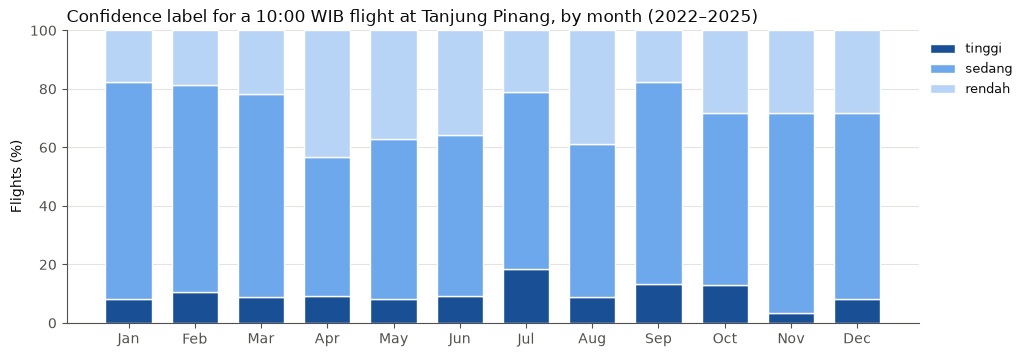

In [6]:
HOURLY = kw.fetch_weatherkit_hourly(date(2021, 12, 31), date(2025, 12, 31), forever=True)
site_wk = SiteWeatherKit(HOURLY)
rows = []
for day in pd.date_range("2022-01-01", "2025-12-31").date:
    r = conf.confidence_for_scan(flight(day, at=time(10, 0)), PLOT, NORMALS, weatherkit=site_wk, nasa_fetch=site_nasa,
                                 computed_at="backcast")
    rows.append({"day": day, "confidence": r["confidence"], "label": r["label"], "final": r["final"],
                 "cloud cover": r["factors"]["cloud"].get("cover"), "rain 6 h": r["factors"]["wet"].get("last_6h_mm"),
                 "rain 24 h": r["factors"]["wet"].get("last_24h_mm")}
                | {f"{k} class": f["class"] for k, f in r["factors"].items()}
                | {f"{k} factor": f["value"] for k, f in r["factors"].items()})
backcast = pd.DataFrame(rows).set_index("day")
month = pd.to_datetime(backcast.index).month
MONTHS = pd.to_datetime([f"2000-{m}-1" for m in range(1, 13)]).strftime("%b")

labels = ["tinggi", "sedang", "rendah"]
share = (pd.crosstab(np.asarray(month), backcast["label"].to_numpy(), normalize="index") * 100).reindex(columns=labels).fillna(0)
share.columns.name = None
share.index = MONTHS
print(f"{len(backcast)} flights · final {backcast['final'].mean():.0%} · " +
      " · ".join(f"{l} {(backcast['label'] == l).mean():.0%}" for l in labels) +
      f" · median confidence {backcast['confidence'].median():.2f}")
display(share.round(0).astype(int).T)

pulled = pd.DataFrame({name: (backcast[f"{name} factor"] < 1).groupby(month).mean() * 100
                       for name in ("sun", "cloud", "wet", "water")})
pulled.index = MONTHS
print("Days each factor is under 1, % of the month:")
display(pulled.round(0).astype(int).T)
print("Classes over the four years:")
for name in ("cloud", "wet", "water"):
    print(f"  {name}: " + ", ".join(f"{k} {v:.0%}" for k, v in backcast[f"{name} class"].value_counts(normalize=True).items()))

colors = {"tinggi": "#184f95", "sedang": "#6da7ec", "rendah": "#b7d3f6"}  # one hue, darker = more confidence
fig, ax = plt.subplots(figsize=(11, 3.8))
bottom = np.zeros(12)
for label in labels:
    ax.bar(range(12), share[label], bottom=bottom, color=colors[label], width=0.7, label=label, edgecolor="white", linewidth=1)
    bottom += share[label].to_numpy()
ax.set_xticks(range(12), MONTHS)
ax.set_ylim(0, 100)
ax.set_ylabel("Flights (%)")
ax.set_title(f"Confidence label for a 10:00 WIB flight at {SITE_NAME}, by month (2022–2025)", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
plt.show()

**What we found** *(run on 14 Oct 2026)*

- Of 1,461 flights at 10:00, **10% tinggi, 62% sedang, 28% rendah**; median confidence 0.59. Every input was known every time.
- **Cloud lowers the confidence on almost every flight** (98–100% each month). WeatherKit almost never puts 10:00 under the 0.2 "clear" line (1% of days), so the factor mostly tells broken cloud (0.7) from overcast (0.85).
- **Wet leaves** come next: 61% of mornings had at least 0.5 mm in the 6 hours before, most in November–December (77–88%) and April (68%).
- **Water** rarely matters here: water stress on 1% of days, the NASA POWER fallback on 2%. June's 23% is that fallback after the day missing from the saved 2023 history (1 Jun); the job's retry now recovers it.
- The best months are July (19% tinggi) and September–October (13%); the worst are April (43% rendah) and August (39%).

**How sensitive is this to the guessed lines?** The cloud and wet-leaf factors are guesses. Below: what WeatherKit actually shows at 10:00 WIB over these four years, and what share of flights each factor would mark at a few other lines. This doesn't change the rule; it is material for choosing the lines.

In [7]:
cover, rain6 = backcast["cloud cover"].astype(float), backcast["rain 6 h"].astype(float)
pct = [10, 25, 50, 75, 90]
display(pd.DataFrame({"cloud cover at 10:00": np.percentile(cover, pct), "rain in the 6 h before (mm)": np.percentile(rain6, pct)},
                     index=[f"{p}th percentile" for p in pct]).round(2).T)
lines = pd.DataFrame({
    "clear if cover ≤": {t: f"{(cover <= t).mean():.0%}" for t in (0.2, 0.3, 0.4, 0.5)},
}).rename_axis("line")
display(lines.T)
display(pd.DataFrame({"wet if 6 h rain ≥ (mm)": {t: f"{(rain6 >= t).mean():.0%}" for t in (0.5, 1, 2, 5)}}).rename_axis("line").T)

,10th percentile,25th percentile,50th percentile,75th percentile,90th percentile
cloud cover at 10:00,0.45,0.60,0.77,0.88,0.96
rain in the 6 h before (mm),0.01,0.17,0.93,2.77,5.69


line,0.2,0.3,0.4,0.5
clear if cover ≤,1%,2%,7%,15%


line,0.5,1.0,2.0,5.0
wet if 6 h rain ≥ (mm),61%,49%,32%,13%


**What we found** *(run on 14 Oct 2026)*

- WeatherKit's cloud cover at 10:00: 0.45 at the 10th percentile, **0.77 at the median**, 0.96 at the 90th. A "clear" line at 0.2 marks 1% of flights clear; at 0.4, 7%; at 0.5, 15%.
- Rain in the 6 hours before: **0.93 mm at the median**, 2.8 mm at the 75th percentile. A wet line at 0.5 mm marks 61% of flights; at 2 mm, 32%; at 5 mm, 13%.
- WeatherKit's hours are model values and may run cloudier and drizzlier than the sky over the plot. So the lines should be chosen against real flights, not against this backcast: fly one block twice within a few days under different skies, and compare the change in VARI per crown with the change in confidence.

### Where this leaves us *(run on 14 Oct 2026)*

| | Status |
| --- | --- |
| VARI per crown on the sample photo | Demo only: boxes instead of SAM masks, no capture time |
| Confidence rule on the backend | Built: `l6_vari_confidence.py`, tests, CLI |
| WeatherKit hourly history | Verified: past hours available, 240 per request |
| Live example scan (1 Jun 2023, 09:40 WIB) | 0.60 sedang: overcast, 11.7 mm before take-off |
| Sun | Factor 1 all year for flights at 10:00–14:00 WIB |
| Cloud and wet-leaf lines | **Open:** as guessed they mark 99% and 61% of 10:00 flights |
| Water | Rarely matters at this site (water stress 1% of days) |

**Recommendations**
- **Use the confidence as a log (L9) for now**, and to rank which scans to trust most. Don't let L6 act on it yet: the cloud and wet-leaf lines aren't calibrated.
- **Tell farmers to fly between 10:00 and 14:00.** The sun is the one factor they control.
- **Calibrate cloud and wet leaves with repeat flights** of one block under different skies.
- **Next, add checks from the photos themselves**: the share of saturated or shadowed pixels in each crown sees the actual light, not a model's estimate of it.

### Open questions

- **Which cloud and wet-leaf lines?** The sensitivity table above is the starting point; repeat flights decide.
- **How far should L6 lower its trust for water stress?** `WATER_FACTOR["water_stress"] = 0.6` is a guess; open since notebook 1.
- **How does the phone upload the scan manifest, and get the result back?** A Swift and infrastructure decision.
- **Are WeatherKit's hourly cloud and rain close to the sky over the plot?** BMKG's hourly station reports, or the drone's own exposure data, would tell.

---
**Attribution.** Weather data: Apple Weather — [other data sources](https://developer.apple.com/weatherkit/data-source-attribution/). These data were obtained from the NASA Langley Research Center (LaRC) POWER Project funded through the NASA Earth Science/Applied Science Program. Sample photo and boxes: the Krops segmentation set (Roboflow export). Raw API responses stay in `data/raw/` (git-ignored).